# Question 2 - Effects of model parameters
We change one parameter at a time using the GBM simulation from Question 1.

## Setup from Question 1
The following parameters and functions are taken from our group notebook so this file can run independently.

In [1]:
# Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Default paramaters
SEED = 460
S0 = 100
K = 95
R = 0.03
Q = 0.02
SIGMA = 0.25
M = 50
T = 0.5
NUM_PATH = 20_000

In [3]:
# Question 1 functions


def GBM(
    initial_stock_price=S0,
    interest_rate=R,
    volatility=SIGMA,
    time_steps=M,
    terminal_time=T,
    dividend_yield=Q,
    num_path=NUM_PATH,
    seed=SEED,
):
    """
    Generate GBM with annualized paramaters
    """

    # Set seed for reproducibility
    rng = np.random.default_rng(seed=seed)
    dt = terminal_time / time_steps

    # Generate all brownian motion paths using standard normal distribution
    Z = rng.standard_normal((time_steps, num_path))

    # Compute log returns for each path and for each time step
    drift = (interest_rate - dividend_yield - 0.5 * volatility**2) * dt
    diffusion = volatility * np.sqrt(dt) * Z
    log_returns = drift + diffusion

    # Cumlate the log returns to get the log stock price
    log_prices = np.vstack([np.zeros(num_path), np.cumsum(log_returns, axis=0)])

    Ws = np.cumsum(np.vstack([np.zeros(num_path), np.sqrt(dt) * Z]), axis=0)

    # Convert log prices to actual stock prices
    stock_prices = initial_stock_price * np.exp(log_prices)

    return stock_prices, Ws


def apply_discount_factor(price, interest_rate=R, terminal_time=T):
    """
    Discount the price of an option to present value
    """
    return price * np.exp(-interest_rate * terminal_time)


def Undiscounted_Asian_Put(
    strike_price=K,
    initial_stock_price=S0,
    interest_rate=R,
    volatility=SIGMA,
    time_steps=M,
    terminal_time=T,
    dividend_yield=Q,
    num_path=NUM_PATH,
    seed=SEED,
):
    """
    Generate undiscounted payoff for Asian put option where stock prices are modeled using GBM
    """
    # Compute the stock price paths using GBM
    stock_prices, _ = GBM(
        initial_stock_price,
        interest_rate,
        volatility,
        time_steps,
        terminal_time,
        dividend_yield,
        num_path,
        seed,
    )

    # Compute the payoff of the Asian put option for each path
    average_prices = np.mean(stock_prices[1:, :], axis=0)
    payoffs = np.maximum(strike_price - average_prices, 0)

    return payoffs


def Monte_Carlo_Simulation(
    strike_price=K,
    initial_stock_price=S0,
    interest_rate=R,
    volatility=SIGMA,
    time_steps=M,
    terminal_time=T,
    dividend_yield=Q,
    num_path=NUM_PATH,
    seed=SEED,
):
    put_payoffs = Undiscounted_Asian_Put(
        strike_price,
        initial_stock_price,
        interest_rate,
        volatility,
        time_steps,
        terminal_time,
        dividend_yield,
        num_path,
        seed,
    )
    put_prices = apply_discount_factor(put_payoffs, interest_rate, terminal_time)

    return put_prices, np.mean(put_prices)

## European put
We use the Black-Scholes European put price with continuous dividend yield as a benchmark. Unlike the Asian put, its payoff only depends on the terminal stock price.

In [5]:
from scipy.stats import norm


def European_Put(strike_price=K, initial_stock_price=S0,
                 interest_rate=R, volatility=SIGMA,
                 terminal_time=T, dividend_yield=Q):
    d1 = (np.log(initial_stock_price / strike_price)
          + (interest_rate - dividend_yield + volatility**2 / 2)
          * terminal_time) / (volatility * np.sqrt(terminal_time))
    d2 = d1 - volatility * np.sqrt(terminal_time)
    return (strike_price * np.exp(-interest_rate * terminal_time) * norm.cdf(-d2)
            - initial_stock_price * np.exp(-dividend_yield * terminal_time) * norm.cdf(-d1))

_, asian_price = Monte_Carlo_Simulation()
print(f"Asian put: {asian_price:.4f}")
print(f"European put: {European_Put():.4f}")

Asian put: 1.8680
European put: 4.4126


## Sensitivity analysis
We keep the seed at 460 and use 20,000 paths for each experiment. When $m$ is fixed, the normal draws stay the same.

In [7]:
results = {}

# Effect of S0
rows = []
for value in [80, 90, 100, 110, 120]:
    _, asian = Monte_Carlo_Simulation(initial_stock_price=value)
    european = European_Put(initial_stock_price=value)
    rows.append([value, asian, european])
results["S0"] = pd.DataFrame(rows, columns=["S0", "Asian put", "European put"])

# Effect of K
rows = []
for value in [75, 85, 95, 105, 115]:
    _, asian = Monte_Carlo_Simulation(strike_price=value)
    european = European_Put(strike_price=value)
    rows.append([value, asian, european])
results["K"] = pd.DataFrame(rows, columns=["K", "Asian put", "European put"])

# Effect of r
rows = []
for value in [0.01, 0.02, 0.03, 0.04, 0.05]:
    _, asian = Monte_Carlo_Simulation(interest_rate=value)
    european = European_Put(interest_rate=value)
    rows.append([value, asian, european])
results["r"] = pd.DataFrame(rows, columns=["r", "Asian put", "European put"])

# Effect of q
rows = []
for value in [0, 0.01, 0.02, 0.03, 0.04]:
    _, asian = Monte_Carlo_Simulation(dividend_yield=value)
    european = European_Put(dividend_yield=value)
    rows.append([value, asian, european])
results["q"] = pd.DataFrame(rows, columns=["q", "Asian put", "European put"])

# Effect of sigma
rows = []
for value in [0.1, 0.15, 0.25, 0.35, 0.45]:
    _, asian = Monte_Carlo_Simulation(volatility=value)
    european = European_Put(volatility=value)
    rows.append([value, asian, european])
results["sigma"] = pd.DataFrame(rows, columns=["sigma", "Asian put", "European put"])

# Effect of T
rows = []
for value in [0.1, 0.25, 0.5, 0.75, 1]:
    _, asian = Monte_Carlo_Simulation(terminal_time=value)
    european = European_Put(terminal_time=value)
    rows.append([value, asian, european])
results["T"] = pd.DataFrame(rows, columns=["T", "Asian put", "European put"])

# Effect of m
rows = []
for value in [1, 2, 5, 10, 25, 50, 100, 200]:
    _, asian = Monte_Carlo_Simulation(time_steps=value)
    european = European_Put()
    rows.append([value, asian, european])
results["m"] = pd.DataFrame(rows, columns=["m", "Asian put", "European put"])

for table in results.values():
    print(table.round(4).to_string(index=False))
    print()

 S0  Asian put  European put
 80    14.7449       15.7878
 90     6.5731        8.9197
100     1.8680        4.4126
110     0.3156        1.9314
120     0.0336        0.7606

  K  Asian put  European put
 75     0.0046        0.3069
 85     0.1951        1.4766
 95     1.8680        4.4126
105     6.9191        9.5621
115    14.9861       16.6812

   r  Asian put  European put
0.01     2.0307        4.8077
0.02     1.9479        4.6071
0.03     1.8680        4.4126
0.04     1.7905        4.2242
0.05     1.7154        4.0419

   q  Asian put  European put
0.00     1.7327        4.0825
0.01     1.7995        4.2454
0.02     1.8680        4.4126
0.03     1.9382        4.5841
0.04     2.0104        4.7599

 sigma  Asian put  European put
  0.10     0.1719        0.8235
  0.15     0.6184        1.9229
  0.25     1.8680        4.4126
  0.35     3.2867        7.0166
  0.45     4.7672        9.6513

   T  Asian put  European put
0.10     0.2855        1.1712
0.25     0.9572        2.6630
0.50 

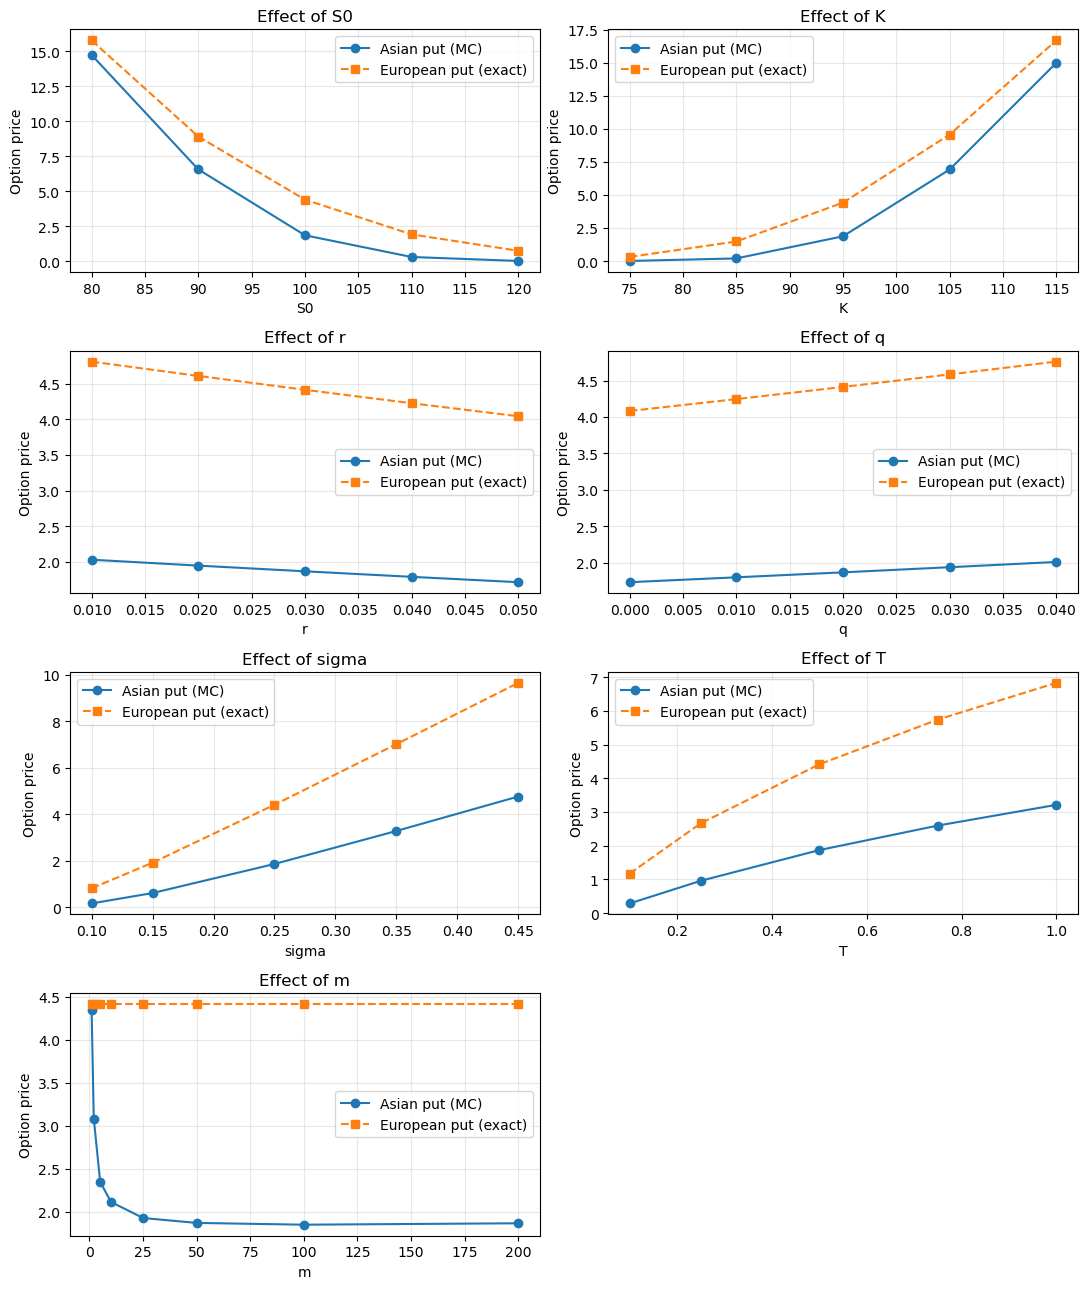

In [9]:
fig, axes = plt.subplots(4, 2, figsize=(11, 13))
for ax, (label, table) in zip(axes.flat, results.items()):
    ax.plot(table[label], table["Asian put"], "o-", label="Asian put (MC)")
    ax.plot(table[label], table["European put"], "s--", label="European put (exact)")
    ax.set_xlabel(label)
    ax.set_ylabel("Option price")
    ax.set_title("Effect of " + label)
    ax.legend()
    ax.grid(alpha=0.3)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

## Check for m = 1
With one averaging date, both payoffs must be identical when calculated on the same paths.

In [11]:
asian_payoffs, asian_m1 = Monte_Carlo_Simulation(time_steps=1)
stock_prices, _ = GBM(time_steps=1)
european_payoffs = apply_discount_factor(np.maximum(K - stock_prices[-1], 0))
print("Asian put (m = 1):", asian_m1)
print("European put (MC):", np.mean(european_payoffs))


Asian put (m = 1): 4.342028192016181
European put (MC): 4.342028192016181


## Conclusion

- Both put prices decrease with $S_0$ and $r$, and increase with $K$ and $q$.
- Both prices increase with $\sigma$ and $T$ over the tested ranges. The Asian put is less sensitive due to averaging.
- As $m$ increases, the Asian put price initially decreases and then stabilizes. The European put price stays constant. At $m=1$, both payoffs are identical.

Small fluctuations may be due to Monte Carlo sampling error.

# Question 3 - Discretization error
We compare exact GBM simulation with the Euler scheme for the parameters in Question 1.

## Euler scheme
Following the Week 8 notes, we use

\(S_{i+1}=S_i+(r-q)S_i\Delta t+\sigma S_i\Delta W_i,\)

where $\Delta W_i=\sqrt{\Delta t}Z_i$. We keep the 50 monitoring dates fixed and use more simulation steps between them.

In [14]:
from time import perf_counter

def Euler_Asian_Put(Z):
    time_steps, num_path = Z.shape
    dt = T / time_steps
    substeps = time_steps // M
    S = np.full(num_path, S0, dtype=float)
    average_prices = np.zeros(num_path)

    for i in range(time_steps):
        S = S * (1 + (R - Q)*dt + SIGMA*np.sqrt(dt)*Z[i])
        if (i + 1) % substeps == 0:
            average_prices += S / M

    return apply_discount_factor(np.maximum(K - average_prices, 0))


def Exact_Asian_Put(Z):
    # Z contains normal draws at the monitoring dates
    dt = T / M
    log_returns = (R - Q - SIGMA**2 / 2)*dt + SIGMA*np.sqrt(dt)*Z
    stock_prices = S0 * np.exp(np.cumsum(log_returns, axis=0))
    return apply_discount_factor(np.maximum(K - stock_prices.mean(axis=0), 0))

_, exact_price = Monte_Carlo_Simulation()
print(f"Question 1 exact MC price: {exact_price:.4f}")

Question 1 exact MC price: 1.8680


## Comparison of prices and computation time
We use the same Brownian increments for the exact and Euler methods in each experiment. Fine increments are added together to obtain the increments at the monitoring dates. Timing is for pricing given the normal draws (excluding random number generation and aggregation).

In [16]:
q3_rows = []
for time_steps in [50, 100, 250, 500, 1000]:
    rng = np.random.default_rng(SEED)
    Z = rng.standard_normal((time_steps, NUM_PATH))
    substeps = time_steps // M
    Z_exact = Z.reshape(M, substeps, NUM_PATH).sum(axis=1) / np.sqrt(substeps)

    start = perf_counter()
    exact = Exact_Asian_Put(Z_exact)
    exact_time = perf_counter() - start

    start = perf_counter()
    euler = Euler_Asian_Put(Z)
    euler_time = perf_counter() - start

    difference = euler - exact
    bias = np.mean(difference)
    se = np.std(difference, ddof=1) / np.sqrt(NUM_PATH)
    q3_rows.append([time_steps, T/time_steps, np.mean(exact), np.mean(euler),
                 bias, se, exact_time, euler_time])
    del Z, Z_exact

q3_results = pd.DataFrame(q3_rows, columns=["Steps", "dt", "Exact put", "Euler put",
                                     "Estimated bias", "Bias SE", "Exact time (s)", "Euler time (s)"])
print(q3_results.round(6).to_string(index=False))

 Steps     dt  Exact put  Euler put  Estimated bias  Bias SE  Exact time (s)  Euler time (s)
    50 0.0100   1.867978   1.873718        0.005741 0.000640        0.049155        0.008215
   100 0.0050   1.873022   1.876269        0.003246 0.000455        0.061900        0.013034
   250 0.0020   1.906165   1.907347        0.001182 0.000288        0.061008        0.029385
   500 0.0010   1.915314   1.915743        0.000430 0.000202        0.060829        0.044210
  1000 0.0005   1.918057   1.918318        0.000261 0.000142        0.058209        0.091128


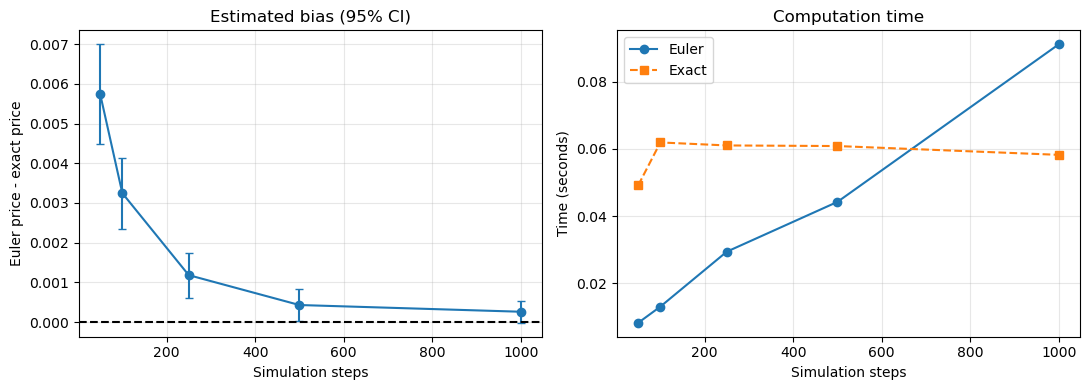

In [18]:
%matplotlib inline
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].errorbar(q3_results["Steps"], q3_results["Estimated bias"],
                 yerr=1.96*q3_results["Bias SE"], fmt="o-", capsize=3)
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set_xlabel("Simulation steps")
axes[0].set_ylabel("Euler price - exact price")
axes[0].set_title("Estimated bias (95% CI)")
axes[1].plot(q3_results["Steps"], q3_results["Euler time (s)"], "o-", label="Euler")
axes[1].plot(q3_results["Steps"], q3_results["Exact time (s)"], "s--", label="Exact")
axes[1].set_xlabel("Simulation steps")
axes[1].set_ylabel("Time (seconds)")
axes[1].set_title("Computation time")
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Check
At 50 steps the exact method should reproduce Question 1.

In [20]:
print("Same exact price as Q1:", np.isclose(q3_results.loc[0, "Exact put"], exact_price))

Same exact price as Q1: True


## Conclusion:

- The Euler price is close to the exact price. The estimated bias generally becomes smaller with finer steps, though sampling error can cause fluctuations.
- More Euler steps require more computation. Exact simulation avoids time discretization bias and is preferable for GBM.
- Timing is based on a single run and may vary.